In [150]:
library( ggplot2 )
set.seed( 1234 ) # Important for reproducibility!

mytheme = function( font_size = 24 ) {
    (
        theme_minimal( font_size, base_family = "gill sans" )
        + theme(
            axis.title.y = element_text( angle = 0, hjust = 1, vjust = 0.5 )
        )
    )
}



In [ ]:
# Fair dice
#simulate_two_dice <- function( number_of_rolls ) {
#    die1 = sample( 1:6, size = number_of_rolls, replace = TRUE )
#    die2 = sample( 1:6, size = number_of_rolls, replace = TRUE )
#    return(
#            roll = 1:number_of_rolls,
##        tibble::tibble(
#            sum_of_dice = die1 + die2
#        )
#    )
#}

# Possibly unfair dice
# weighted by a 'die model' whiuch by default is fair
simulate_two_dice <- function(
    number_of_rolls,
    die_model = rep( 1/6, 6 ) # must sum to 1!
) {
    die1 = sample( 1:6, size = number_of_rolls, replace = T, prob = die_model )
    die2 = sample( 1:6, size = number_of_rolls, replace = T, prob = die_model )
    return(
        tibble::tibble(
            roll = 1:number_of_rolls,
            sum_of_dice = die1 + die2
        )
    )
}


# simulate_two_dice( 100 )



sample_mean,sample_variance
<dbl>,<dbl>
6.82,6.775354


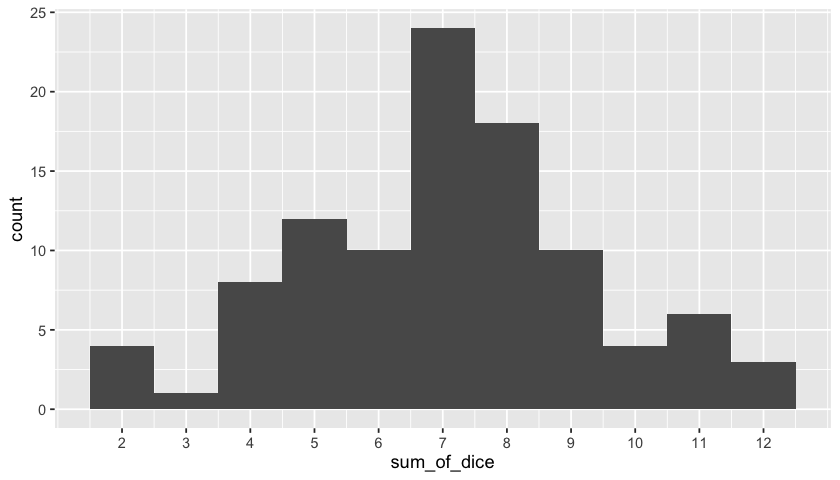

In [118]:
# You could histogram
library( tidyverse )
options( repr.plot.height = 4 )
(
    ggplot( data = simulate_two_dice( 100 ) )
    + geom_histogram(
        aes( x = sum_of_dice ),
        breaks = (2:13) - 0.5
    )
    + scale_x_continuous( breaks = 2:12 )
)

(
    simulate_two_dice( 100 )
    %>% summarise(
        sample_mean     = mean( sum_of_dice ),
        sample_variance = var( sum_of_dice )
    )
)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”


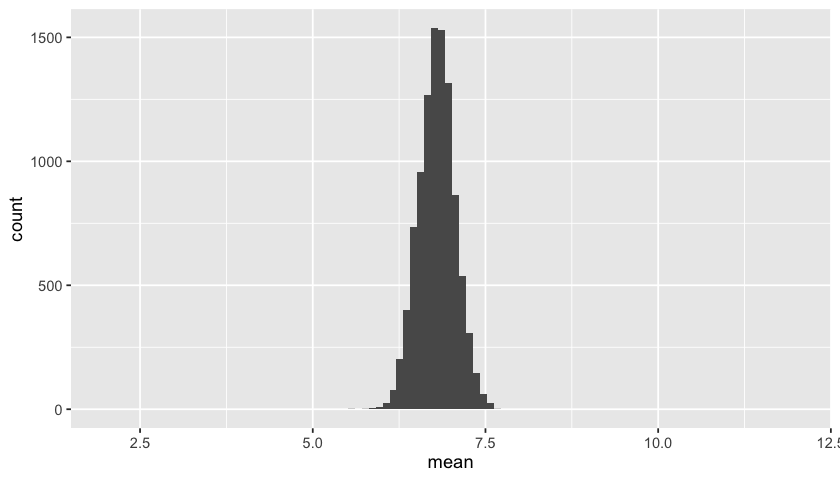

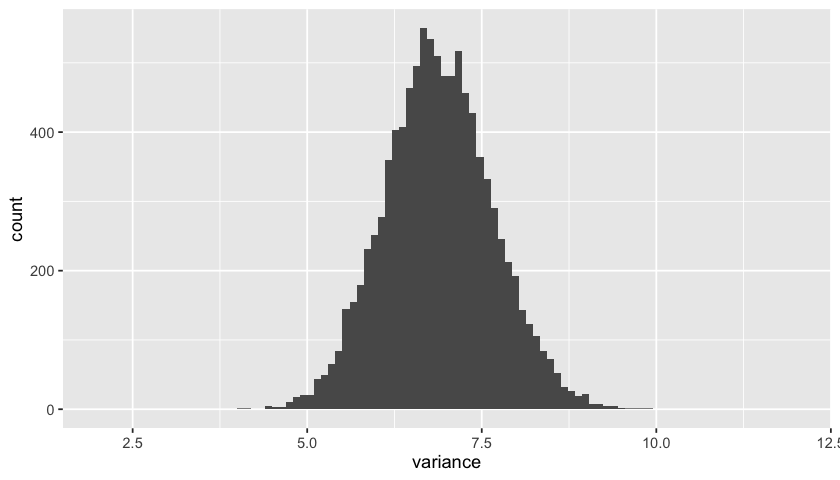

In [142]:
# How much variation is there in the summary statistics?

variation = (
    tibble::tibble( attempt = 1:10000 )
    %>% group_by( attempt )
    # reframe() is like summarise(), but you can return multiple values:
    %>% reframe(
        simulate_two_dice( number_of_rolls = 100, die_model = c( 0.2, 0.2, 0.2, 0, 0.2, 0.2 ))
    )
    %>% group_by( attempt )
    %>% summarise(
        mean     = mean( sum_of_dice ),
        variance = var( sum_of_dice )
    )
)

ggplot( data = variation ) + geom_histogram( aes( x = mean ), bins = 100 ) + xlim( c( 2, 12 ))

ggplot( data = variation ) + geom_histogram( aes( x = variance ), bins = 100 ) + xlim( c( 2, 12 ))


In [135]:
# Possibly unfair dice
# weighted by a 'die model' whiuch by default is fair
simulate_two_dice <- function(
    number_of_rolls,
    die_model = rep( 1/6, 6 ) # must sum to 1!
) {
    die1 = sample( 1:6, size = number_of_rolls, replace = T, prob = die_model )
    die2 = sample( 1:6, size = number_of_rolls, replace = T, prob = die_model )
    return(
        tibble::tibble(
            roll = 1:number_of_rolls,
            sum_of_dice = die1 + die2
        )
    )
}

two_dice_likelihood <- function(
    x,                                     # sum of dice to evaluate on
    die_model = rep( 1/6, 6 )          # dice model as in simulate_two_dice
) {
    dice1 = tibble::tibble( dice1 = 1:6, dice1_probability = die_model )
    dice2 = tibble::tibble( dice2 = 1:6, dice2_probability = die_model )
    both_dice = (
        dice1
        %>% cross_join( dice2 )
        %>% mutate(
            sum_of_dice = dice1 + dice2,
            probability = dice1_probability * dice2_probability
        )
    )
    by_result = (
        both_dice
        %>% group_by( sum_of_dice )
        %>% summarise(
            number_of_ways = n(),
            probability = sum( probability )
        )
    )

    result = (
        tibble::tibble( sum_of_dice = x )
        %>% left_join( by_result, by = "sum_of_dice" )
    )

    return( result )
}


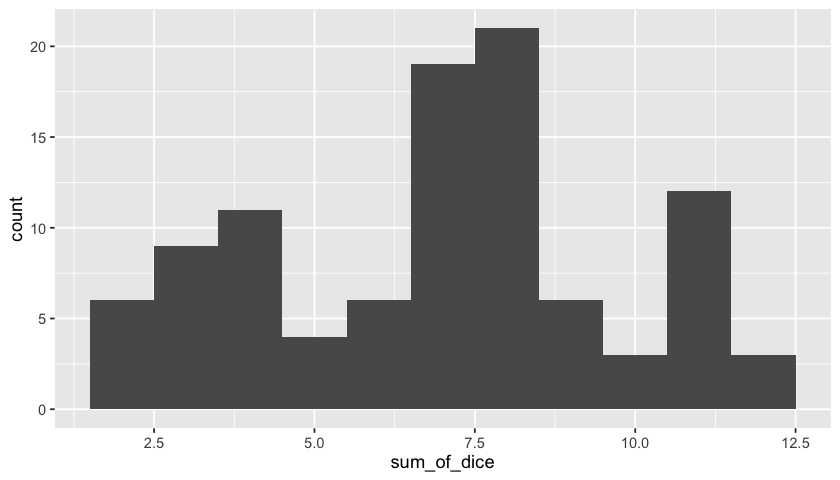

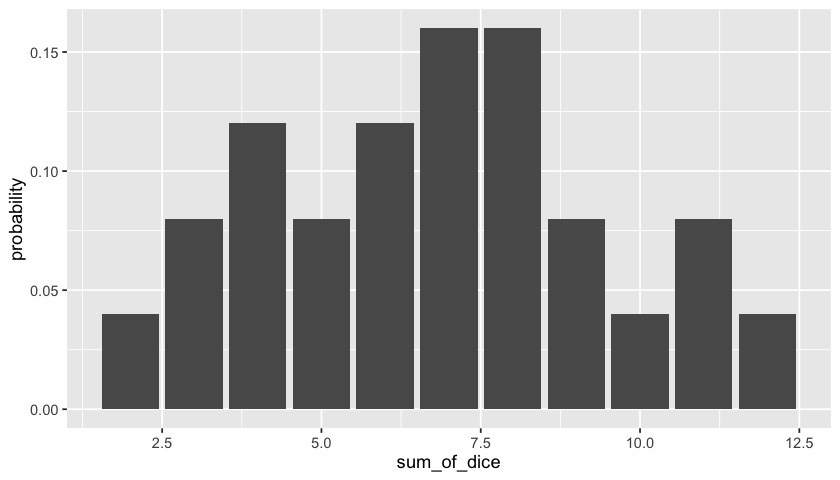

In [140]:
(
    ggplot(
        data = simulate_two_dice(
            100,
            die_model = c( 0.2, 0.2, 0.2, 0, 0.2, 0.2 )
        )
    )
    + geom_histogram(
        aes( x = sum_of_dice ),
        breaks = (2:13)-0.5
    )
)

(
    ggplot(
        data = two_dice_likelihood(
            2:12,
            die_model = c( 0.2, 0.2, 0.2, 0, 0.2, 0.2 )
        )
    )
    + geom_col(
        aes( x = sum_of_dice, y = probability )
    )
)

# Summary statistics?



In [143]:
data = readr::read_tsv( "https://users.ox.ac.uk/~whgu0376/training/msc_gm/2026/data/dice_data1.tsv" )

Rows: 30 Columns: 2
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
dbl (2): roll, sum_of_dice

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [145]:
print( data, n = 100 )

# A tibble: 30 × 2
    roll sum_of_dice
   <dbl>       <dbl>
 1     1           8
 2     2           6
 3     3           8
 4     4           5
 5     5           8
 6     6          11
 7     7          11
 8     8          11
 9     9           6
10    10           8
11    11           7
12    12           5
13    13           5
14    14          11
15    15           6
16    16           7
17    17           7
18    18           7
19    19          10
20    20           3
21    21          10
22    22          12
23    23           9
24    24           7
25    25           7
26    26           6
27    27           7
28    28           8
29    29           3
30    30          12


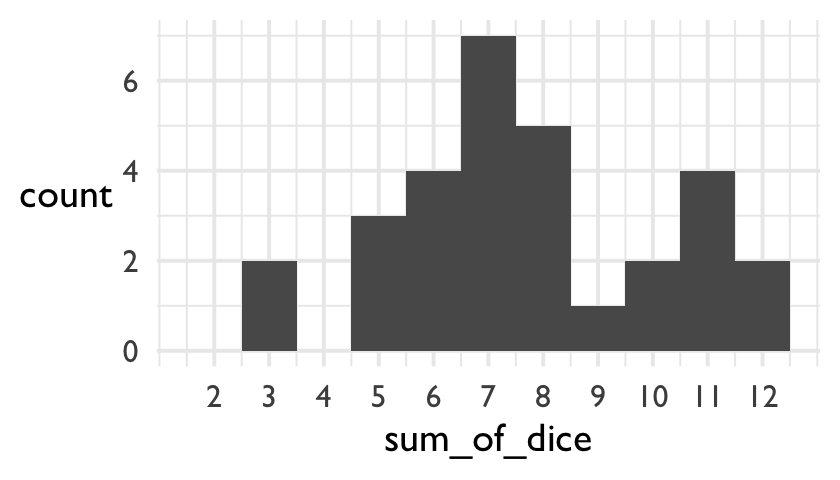

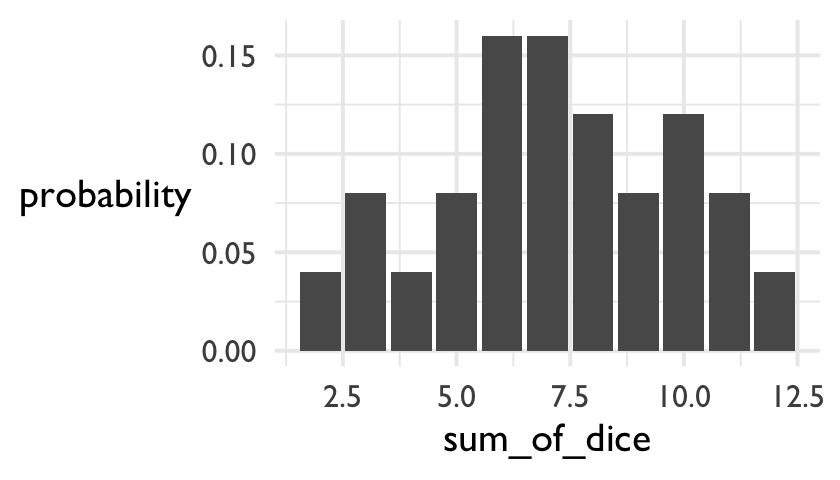

In [183]:
(
    ggplot( data = data )
    + geom_histogram( aes( x = sum_of_dice ), breaks = c( 2:13-0.5 ))
    + scale_x_continuous( breaks = 2:12 )
    + mytheme()
)

# Plot likelihood for 'omit 5' (blu-tack on 2) model
(
    ggplot( data = two_dice_likelihood( 2:12, die_model = c( 0.2, 0.2, 0, 0.2, 0.2, 0.2 )))
    + geom_col( aes( x = sum_of_dice, y = probability ))
    + mytheme()
)

In [169]:
# Function to compute overall likelihood
total_likelihood = function( sum_of_dice, die_model = rep( 1/6, 6 ) ) {
    prod(
        two_dice_likelihood( sum_of_dice, die_model )$probability
    )
}

# Likelihood of getting 2, 3, 4, ..., 10
total_likelihood( 2:10 )

total_likelihood( data$sum_of_dice )

1 + 10^-30

[1] 4.253645e-10

[1] 1.649591e-30

[1] 1

In [170]:
total_loglikelihood = function( sum_of_dice, die_model = rep( 1/6, 6 ) ) {
    sum(
        log(
            two_dice_likelihood( sum_of_dice, die_model )$probability
        )
    )
}

# Log-likelihood under fair dice model
total_loglikelihood( data$sum_of_dice )

# Log-likelihood under 'omit 5' (blu-tack on 2) model:
total_loglikelihood( data$sum_of_dice, die_model = c( 0.2, 0.2, 0.2, 0.2, 0, 0.2 ))


[1] -68.57703

[1] -Inf

In [171]:
# Full inference
models = tibble::tribble(
    ~model,          ~p1, ~p2, ~p3, ~p4, ~p5, ~p6,
    "normal dice",   1/6, 1/6, 1/6, 1/6, 1/6, 1/6,
    "Omit 1",          0, 0.2, 0.2, 0.2, 0.2, 0.2,
    "Omit 2",        0.2,   0, 0.2, 0.2, 0.2, 0.2,
    "Omit 3",        0.2, 0.2,   0, 0.2, 0.2, 0.2,
    "Omit 4",        0.2, 0.2, 0.2,   0, 0.2, 0.2,
    "Omit 5",        0.2, 0.2, 0.2, 0.2,   0, 0.2,
    "Omit 6",        0.2, 0.2, 0.2, 0.2, 0.2,   0,
)

# We work in log space so need log_sum_exp() to add probabilities
# represented as logs
log_sum_exp = function( log_values ) {
    a = max( log_values )
    a + log( sum( exp(log_values - a)))
}


compute_posteriors = function(
    data,
    models,
    prior = rep( 1/nrow(models), length( models ))
) {
    (
        models
        %>% mutate( prior = prior )
        %>% group_by( model )
        %>% mutate(
            loglikelihood = total_loglikelihood( data$sum_of_dice, c( p1, p2, p3, p4, p5, p6 ))
        )
        %>% mutate(
            log_prior = log(prior)
        )
        %>% mutate(
            log_normalising_constant = log_sum_exp( log(prior) + loglikelihood)
        )
        %>% mutate(
            posterior = exp(
                (log_prior + loglikelihood) - log_normalising_constant
            )
        )
    )
}



In [181]:
posteriors = compute_posteriors(
    data,
    models,
    prior = rep( 1/6, nrow( models ))
)

posteriors$posterior[ is.na(posteriors$posterior)] = 0
print( posteriors, width = 1000 )


# A tibble: 7 × 12
# Groups:   model [7]
  model          p1    p2    p3    p4    p5    p6 prior loglikelihood log_prior
  <chr>       <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>         <dbl>     <dbl>
1 normal dice 0.167 0.167 0.167 0.167 0.167 0.167 0.167         -68.6     -1.79
2 Omit 1      0     0.2   0.2   0.2   0.2   0.2   0.167        -Inf       -1.79
3 Omit 2      0.2   0     0.2   0.2   0.2   0.2   0.167        -Inf       -1.79
4 Omit 3      0.2   0.2   0     0.2   0.2   0.2   0.167         -66.7     -1.79
5 Omit 4      0.2   0.2   0.2   0     0.2   0.2   0.167         -68.6     -1.79
6 Omit 5      0.2   0.2   0.2   0.2   0     0.2   0.167        -Inf       -1.79
7 Omit 6      0.2   0.2   0.2   0.2   0.2   0     0.167        -Inf       -1.79
  log_normalising_constant posterior
                     <dbl>     <dbl>
1                    -70.4         1
2                    NaN           0
3                    NaN           0
4                    -68.5         1
5                

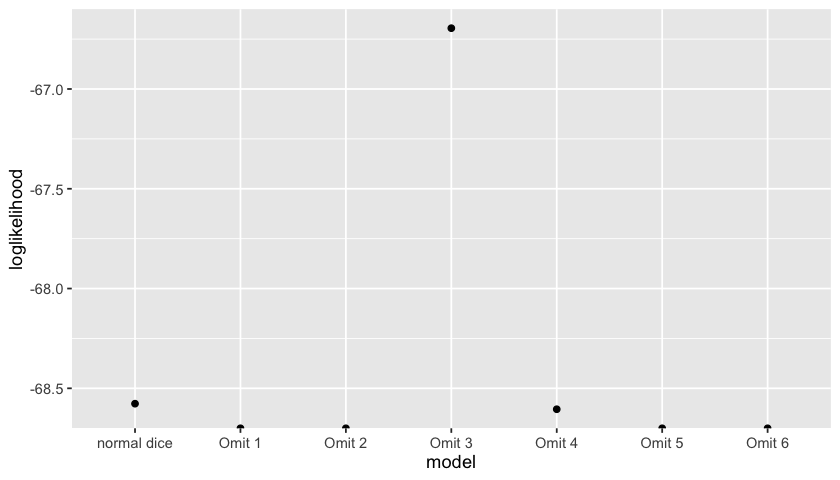

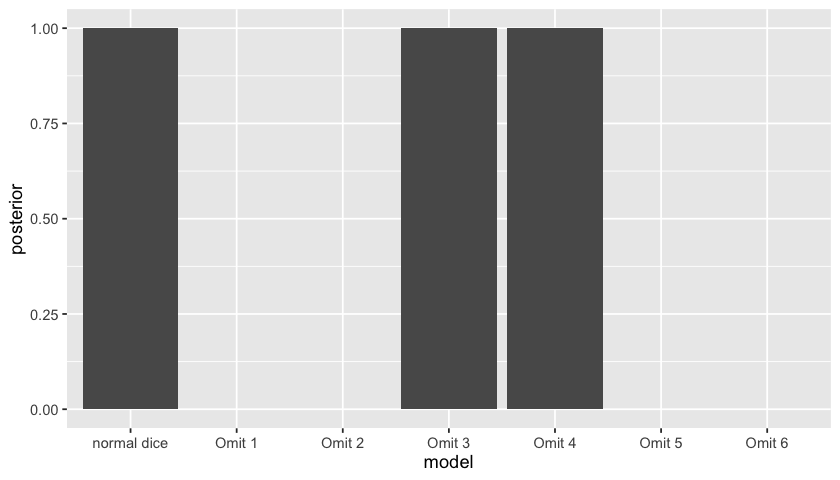

In [182]:

(
    ggplot(
        compute_posteriors(
            data,
            models,
            prior = rep( 1/6, nrow( models ))
        )
    ) + geom_point(
        aes( x = model, y = loglikelihood )
    )
)

(
    ggplot(
        posteriors
    ) + geom_col(
        aes( x = model, y = posterior )
    )
)



In [184]:
data = readr::read_tsv(
    "https://raw.githubusercontent.com/chg-training/chg-training-resources/main/docs/statistical_modelling/introduction/data/1000_genomes_o_blood_group_grouped.tsv"
)

Rows: 29 Columns: 4
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
chr (1): population
dbl (3): C/C, -/C, -/-

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
